# 02 · ¿El funding predice el precio?

**La idea:** cuando el funding está muy alto, hay muchísima gente apostando a la suba (pagan caro por mantener su apuesta). Si el precio no sube, muchos cierran o los liquidan, y eso empuja el precio **para abajo**. Si fuera cierto, un funding muy alto anunciaría bajas.

**La pregunta:** ¿el funding extremo de esta hora predice cuánto se mueve el precio en las **próximas 8 horas**?

Pasos:
1. Calcular, para cada hora, cuánto se movió el precio en las 8 horas **siguientes**.
2. Medir qué tan **extremo** es el funding de cada hora comparado con lo normal de esa semana.
3. Ordenar todas las horas de menor a mayor funding, partirlas en **5 grupos iguales** y ver el movimiento promedio del precio en cada grupo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

COIN = "BTC"   # cambiá a "ETH" o "SOL" para mirar otra moneda
df = pd.read_csv(f"../data/{COIN}.csv", parse_dates=["time"])

## Paso 1: el retorno futuro

`shift(-8)` toma el precio de 8 filas más adelante (8 horas después). El retorno futuro es cuánto cambió en % desde ahora hasta entonces.

**Esta es la variable que queremos predecir.** Ojo: solo se usa para medir; jamás puede entrar en la regla, porque en la vida real el futuro no se conoce.

In [2]:
H = 8  # horizonte en horas: probá también 4 y 24
df["fut_ret"] = df["close"].shift(-H) / df["close"] - 1
df[["time", "close", "fut_ret"]].head(10)

,time,close,fut_ret
0,2026-04-07 00:00:00,68736.0,0.002517
1,2026-04-07 01:00:00,68363.0,0.010942
2,2026-04-07 02:00:00,68648.0,-0.006628
3,2026-04-07 03:00:00,68744.0,-0.006226
4,2026-04-07 04:00:00,68826.0,-0.006742
5,2026-04-07 05:00:00,68628.0,-0.006178
6,2026-04-07 06:00:00,68542.0,-0.010388
7,2026-04-07 07:00:00,68590.0,-0.006648
8,2026-04-07 08:00:00,68909.0,-0.010245
9,2026-04-07 09:00:00,69111.0,-0.006410


## Paso 2: ¿qué tan extremo es el funding? (el *z-score*)

Un funding de 0,001 % puede ser alto en una semana tranquila y normal en una semana loca. Por eso lo comparamos con **su propia semana anterior** (168 horas):

`z = (funding de ahora − promedio de la última semana) / desvío de la última semana`

- `z = 0`: funding normal.
- `z = +2`: mucho más alto de lo habitual.
- `z = −2`: mucho más bajo de lo habitual.

`rolling(168)` calcula el promedio y el desvío usando solo las 168 horas **anteriores**, así no usamos información del futuro.

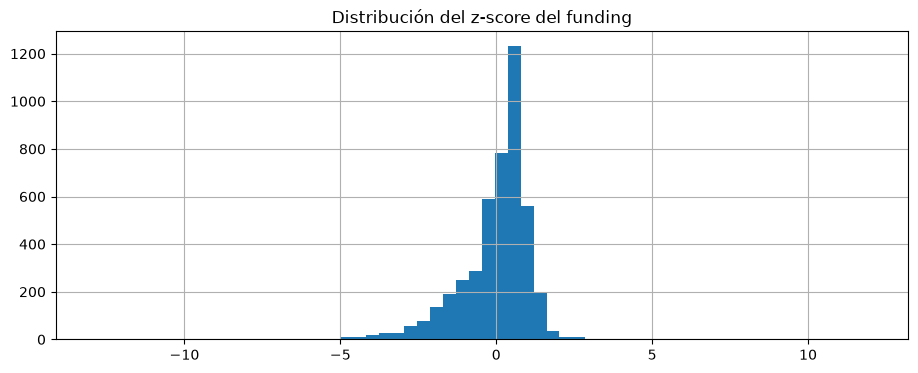

In [3]:
W = 168
media = df["fundingRate"].rolling(W).mean()
desvio = df["fundingRate"].rolling(W).std()
df["z"] = (df["fundingRate"] - media) / desvio

df = df.dropna(subset=["z", "fut_ret"])  # las primeras horas no tienen semana anterior
df["z"].hist(bins=60); plt.title("Distribución del z-score del funding"); plt.show()

## Paso 3: los 5 grupos

`pd.qcut(..., 5)` ordena las horas por su z y las parte en 5 grupos del mismo tamaño:
- Grupo 1: el 20 % de horas con el funding **más bajo**.
- Grupo 5: el 20 % con el funding **más alto**.

Después calculamos el retorno futuro promedio de cada grupo.

         mean %  count
grupo                 
1      0.006510    905
2      0.078440    904
3      0.050819    905
4      0.047926    904
5     -0.081083    905


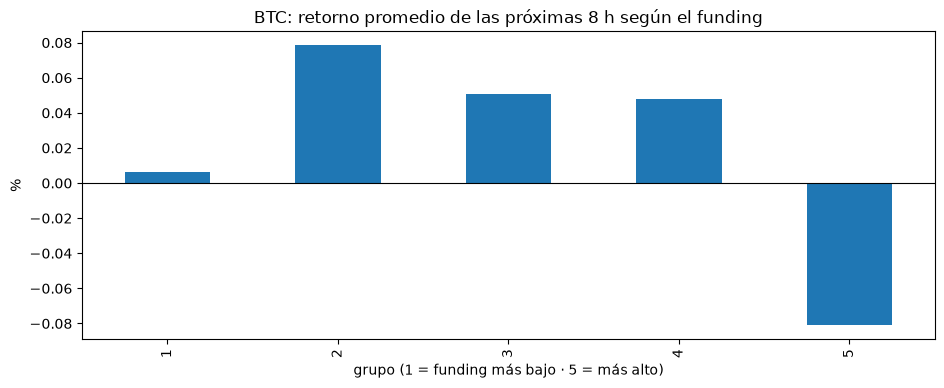

In [4]:
df["grupo"] = pd.qcut(df["z"], 5, labels=[1, 2, 3, 4, 5])
tabla = df.groupby("grupo", observed=True)["fut_ret"].agg(["mean", "count"])
tabla["mean %"] = tabla["mean"] * 100
print(tabla[["mean %", "count"]])

(tabla["mean %"]).plot.bar(title=f"{COIN}: retorno promedio de las próximas {H} h según el funding")
plt.xlabel("grupo (1 = funding más bajo · 5 = más alto)"); plt.ylabel("%"); plt.axhline(0, color="black", lw=0.8); plt.show()

## Cómo leer el gráfico

- **Si las barras bajan de forma ordenada del 1 al 5** (o suben), hay una **posible señal**: el funding dice algo del precio futuro.
- **Si las barras están desordenadas o son todas parecidas**, **no hay señal**. Es un resultado válido y se publica igual.

**Cuidado:** con pocos meses de datos, una diferencia chica puede ser pura casualidad. Por eso existe el notebook 03.

## Extra: ¿se repite en otras monedas?
Si el patrón es real, debería aparecer también en ETH y SOL. Si solo aparece en una, sospechá de casualidad.

In [5]:
for coin in ["BTC", "ETH", "SOL"]:
    d = pd.read_csv(f"../data/{coin}.csv", parse_dates=["time"])
    d["fut_ret"] = d["close"].shift(-H) / d["close"] - 1
    d["z"] = (d["fundingRate"] - d["fundingRate"].rolling(W).mean()) / d["fundingRate"].rolling(W).std()
    d = d.dropna(subset=["z", "fut_ret"])
    g = d.groupby(pd.qcut(d["z"], 5, labels=[1, 2, 3, 4, 5]), observed=True)["fut_ret"].mean() * 100
    print(coin, " · ".join(f"G{k}: {v:+.3f}%" for k, v in g.items()))

BTC G1: +0.007% · G2: +0.078% · G3: +0.051% · G4: +0.048% · G5: -0.081%
ETH G1: +0.059% · G2: -0.050% · G3: +0.022% · G4: -0.222% · G5: +0.179%
SOL G1: -0.047% · G2: +0.204% · G3: -0.083% · G4: -0.004% · G5: +0.154%
